# 📅 **НЕДЕЛЯ 4 (22-28 сентября): Обратные задачи ПДУ**

**Цель**: Научиться решать обратные задачи для ПДУ (найти коэффициент $k$ из данных)

---

## 📚 **ДЕНЬ 1 (22 сентября, 3-4 часа): Обратная задача: теория**

### **Тема дня**: Что такое обратная задача ПДУ?

**Формулы**:

**Прямая задача**:
- Дано: уравнение $\frac{\partial u}{\partial t} = k \cdot \frac{\partial^2 u}{\partial x^2}$
- Дано: коэффициент $k = 0.01$
- Найти: решение $u(x,t)$

**Обратная задача**:
- Дано: уравнение $\frac{\partial u}{\partial t} = k \cdot \frac{\partial^2 u}{\partial x^2}$
- Дано: данные $u(x_i, t_i)$ (из измерений или CFD)
- Найти: коэффициент $k$

**Идея PINN для обратной задачи**:
1. Создать нейросеть: $u_{\text{pred}} = \text{net}(x, t; \theta)$
2. Вычислить производные через autograd: $\frac{\partial u}{\partial t}$, $\frac{\partial^2 u}{\partial x^2}$
3. Вычислить residual: $r = \frac{\partial u}{\partial t} - k \cdot \frac{\partial^2 u}{\partial x^2}$
4. $k$ — обучаемый параметр
5. Loss функция:
   $$
   \mathcal{L} = \underbrace{\frac{1}{N}\sum_{i=1}^{N} (u_{\text{pred}}^{(i)} - u_{\text{true}}^{(i)})^2}_{\mathcal{L}_{\text{data}}} + \underbrace{\frac{1}{N}\sum_{i=1}^{N} r^{(i)2}}_{\mathcal{L}_{\text{physics}}}
   $$
6. Обучить сеть и $k$ одновременно

**Необходимые функции**:
- `torch.nn.Parameter()` — создаёт обучаемый параметр
- `torch.autograd.grad()` — вычисление производных
- `create_graph=True` — для вторых производных

**Практика**:
1. Прочитать теорию (формулы выше)
2. Ответить: в чем разница прямой и обратной задачи?
3. Полюбопытствовать: где это применяется? (подсказка: найти вязкость жидкости из экспериментальных данных)

---

### **заметка про meshgrid**

```python

x = torch.tensor([1, 2, 3])
y = torch.tensor([4, 5, 6])
```

Рассмотрим попарные сочетания элементов в сетке: (1, 4), (1, 5), ..., (3, 6). Это то же самое, что и декартово произведение.

```python
grid_x, grid_y = torch.meshgrid(x, y, indexing='ij')
grid_x
tensor([[1, 1, 1],
        [2, 2, 2],
        [3, 3, 3]])
grid_y
tensor([[4, 5, 6],
        [4, 5, 6],
        [4, 5, 6]])
```

Это соответствие можно увидеть, если правильно наложить эти сетки друг на друга.

```python
torch.equal(torch.cat(tuple(torch.dstack([grid_x, grid_y]))),
            torch.cartesian_prod(x, y))
True
```

`torch.meshgrid` обычно используется для создания сетки для построения графиков.

```python
import matplotlib.pyplot as plt
xs = torch.linspace(-5, 5, steps=100)
ys = torch.linspace(-5, 5, steps=100)
x, y = torch.meshgrid(xs, ys, indexing='xy')
z = torch.sin(torch.sqrt(x * x + y * y))
ax = plt.axes(projection='3d')
ax.plot_surface(x.numpy(), y.numpy(), z.numpy())
plt.show()
```

## 📚 **ДЕНЬ 2 (23 сентября, 3-4 часа): Генерация данных**

### **Тема дня**: Создать $u(x,t)$ через аналитическое решение

**Формулы**:

**Аналитическое решение уравнения теплопроводности**:
$$
u(x,t) = e^{-k \pi^2 t} \cdot \sin(\pi x)
$$
где $k = 0.01$ (коэффициент диффузии)

**Сгенерировать точки**:
- $x = [0, 1]$ с шагом 0.01 (100 точек)
- $t = [0, 1]$ с шагом 0.01 (100 точек)
- Создать сетку: $X_{ij} = x_i$, $T_{ij} = t_j$
- Развернуть в 1D: $x_{\text{flat}}$, $t_{\text{flat}}$ (10000 точек)

**Вычислить $u(x,t)$**:
$$
u_i = e^{-k \pi^2 t_i} \cdot \sin(\pi x_i)
$$
$$
u_i \leftarrow u_i + 0.01 \cdot \varepsilon_i, \quad \varepsilon_i \sim \mathcal{N}(0, 1)
$$

**Построить 3D график**: $x$, $t$, $u$ (поверхность)

**Необходимые функции**:
- `torch.linspace(start, end, steps)`
- `torch.meshgrid(x, t)` — создать сетку
- `torch.flatten()` — развернуть в 1D
- `torch.exp()`, `torch.sin()` — экспонента и синус
- `mpl_toolkits.mplot3d` — 3D график

**Практика**:
1. Реализовать формулы выше
2. Построить 3D поверхность $u(x,t)$
3. Проверить: $u(x,0) = \sin(\pi x)$, $u(x,1) \approx 0$ (распалось)

---

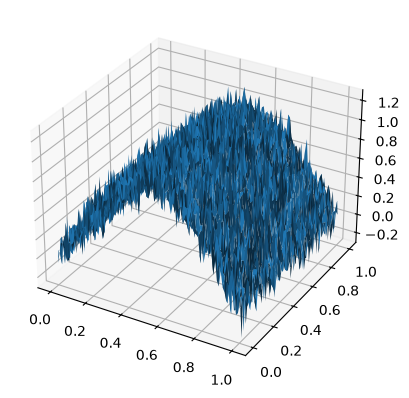

In [ ]:
from math import pi
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import random_split, TensorDataset, DataLoader
import matplotlib.pyplot as plt
import random
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

def u_teor(x, t, k = 0.01):
    u = torch.exp(- k * pi**2 * t) * torch.sin(pi * x) + 0.1*torch.randn_like(x)
    return u

def create_visualization_data(a, b, n):
    #сетка для построения трехмерной картины
    x_nodes = torch.linspace(a, b, n) # узлы сетки по оси х
    t_nodes = torch.linspace(a, b, n) # узлы сетки по оси t

    x, t = torch.meshgrid(x_nodes, t_nodes, indexing='xy') # натянули сетку на узлы 
    return x, t

def create_training_data(n_samples):
    #узлы для обучения NN
    x = torch.rand(n_samples, 1)
    t = torch.rand(n_samples, 1)
    xt_dataset = TensorDataset(x, t)
    n_train, n_val = int(0.8*n_samples), int(0.2*n_samples)
    xt_train_data, xt_val_data = random_split(xt_dataset, [n_train, n_val])
    return xt_train_data, xt_val_data

def visualization3D(a0=a, b0=b, n0=n):
    x_viz, t_viz = create_visualization_data(a0, b0, n0)
    u_true = u_teor(x_viz, t_viz) # рассчитали точное решения во всех узлах сетки 
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    ax.plot_surface(x_viz.numpy(), t_viz.numpy(), u_true.numpy())
    plt.show()



## 📚 **ДЕНЬ 3 (24 сентября, 3-4 часа): Невязка в PyTorch**

### **Тема дня**: Реализовать residual для ПДУ

**Формулы**:

**Архитектура сети**:
$$
u_{\text{pred}} = \text{MLP}(x, t; \theta)
$$
где MLP: $\mathbb{R}^2 \to \mathbb{R}$ (2 входа: $x, t$, 1 выход: $u$)

**Residual уравнения**:
$$
r(x,t) = \frac{\partial u_{\text{pred}}}{\partial t} - k \cdot \frac{\partial^2 u_{\text{pred}}}{\partial x^2}
$$

**Вычисление производных**:
1. $\frac{\partial u}{\partial t}$ — первая производная по $t$
2. $\frac{\partial u}{\partial x}$ — первая производная по $x$
3. $\frac{\partial^2 u}{\partial x^2}$ — вторая производная по $x$

**Необходимые функции**:
- `torch.nn.Parameter()` — обучаемый параметр $k$
- `torch.autograd.grad(outputs, inputs, create_graph=True)`
- `torch.stack([x, t], dim=1)` — объединить входы

**Практика**:
1. Реализовать формулы выше
2. Проверить: $r(x,t)$ не NaN
3. Полюбопытствовать: почему `create_graph=True`? (подсказка: нужны вторые производные)

---

In [ ]:
def create_model():
    return nn.Sequential(
        nn.Linear(1, 64),
        nn.Tanh(),
        nn.Linear(64, 64),
        nn.Tanh(),
        nn.Linear(64, 1),
    )

def train_and_evaluate(x_train, y_train, x_val, y_val):
    model = create_model()
    optimizer = Adam(model.parameters(), lr=0.01, weight_decay=0.01)
    criterion = nn.MSELoss()

    x_train_t = torch.from_numpy(x_train)
    y_train_t = torch.from_numpy(y_train)
    x_val_t = torch.from_numpy(x_val)
    y_val_t = torch.from_numpy(y_val)

    train_losses = []
    val_losses = []

    for _ in range(300):
        model.train()
        optimizer.zero_grad()
        y_pred_train = model(x_train_t)
        train_loss = criterion(y_pred_train, y_train_t)
        train_loss.backward()
        optimizer.step()
        train_losses.append(train_loss.item())

        model.eval()
        with torch.no_grad():
            y_pred_val = model(x_val_t)
            val_loss = criterion(y_pred_val, y_val_t)
            val_losses.append(val_loss.item())

    return model, train_losses, val_losses


def compute_metrics(y_true, y_pred):
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))

    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot

    return mse, rmse, mae, r2


def main():
    np.random.seed(42)
    torch.manual_seed(42)
    a, b = 0.0, 1.0
    n = 100
    xt_train, xt_val = create_training_data(n)

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    all_val_losses = []
    all_metrics = []

    for train_idx, val_idx in kf.split(x):
        x_train = x[train_idx]
        y_train = y[train_idx]
        x_val = x[val_idx]
        y_val = y[val_idx]

        model, train_losses, val_losses = train_and_evaluate(
            x_train, y_train, x_val, y_val
        )

        model.eval()
        with torch.no_grad():
            y_pred = model(torch.from_numpy(x_val)).numpy()

        metrics = compute_metrics(y_val, y_pred)

        all_val_losses.append(val_losses[-1])
        all_metrics.append(metrics)

    mean_val_loss = np.mean(all_val_losses)
    std_val_loss = np.std(all_val_losses)

    r2_scores = [metrics[3] for metrics in all_metrics]
    mean_r2 = np.mean(r2_scores)
    std_r2 = np.std(r2_scores)

    print(f"Mean val_loss: {mean_val_loss:.2f} ± {std_val_loss:.2f}")
    print(f"Mean R²: {mean_r2:.2f} ± {std_r2:.2f}")

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, 6), all_val_losses, "o-", linewidth=2, markersize=8)
    plt.xlabel("Fold number")
    plt.ylabel("Validation loss")
    plt.title("Fold number vs val_loss")
    plt.xticks(range(1, 6))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig("fold_val_loss.png", dpi=150)
    plt.show()


u_true = u_teor(x, t) # рассчитали точное решения во всех узлах сетки 
du_dx = torch.autograd.grad(u_true, x, grad_outputs=torch.ones_like(u_true), create_graph=True) # вычисление grad du/dx
du_dt = torch.autograd.grad(u_true, t, grad_outputs=torch.ones_like(u_true), create_graph=True) # вычисление grad du/dt
d2u_dx2 = torch.autograd.grad(du_dx, x, grad_outputs=torch.ones_like(u_true)) # вычисление grad d2u/dx2

print(du_dx)  # True
print(du_dt)  # True
print(d2u_dx2)


train_data, val_data= create_training_data(n)
visualization3D()



In [ ]:
x = torch.linspace(0, 1, 10, requires_grad=True)
y = (x ** 2)
dy_dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)

print(dy_dx)

In [ ]:


ax = plt.axes(projection='3d')
ax.plot_surface(x.numpy(), t.numpy(), u_true.numpy(), cmap='inferno') #построили поверхность, раскрасили в инферно
plt.show()

## 📚 **ДЕНЬ 4 (25 сентября, 3-4 часа): Autograd для ПДУ**

### **Тема дня**: Вычисление $\frac{\partial u}{\partial t}$, $\frac{\partial^2 u}{\partial x^2}$ через autograd

**Формулы**:

**Тестовая функция**:
$$
u(x,t) = x^2 t + \sin(x t)
$$

**Аналитические производные**:
$$
\frac{\partial u}{\partial t} = x^2 + x \cos(x t)
$$
$$
\frac{\partial u}{\partial x} = 2x t + t \cos(x t)
$$
$$
\frac{\partial^2 u}{\partial x^2} = 2t - t^2 \sin(x t)
$$

**Вычисление через autograd**:
1. Задать $x_i$, $t_i$ с `requires_grad=True`
2. Вычислить $u_i = x_i^2 t_i + \sin(x_i t_i)$
3. $\frac{\partial u}{\partial t} = \text{autograd.grad}(u, t)$
4. $\frac{\partial u}{\partial x} = \text{autograd.grad}(u, x)$
5. $\frac{\partial^2 u}{\partial x^2} = \text{autograd.grad}\left(\frac{\partial u}{\partial x}, x\right)$

**Сравнение**:
$$
\text{error} = \left| \frac{\partial u}{\partial t}_{\text{autograd}} - \frac{\partial u}{\partial t}_{\text{analytic}} \right|
$$
Проверить: $\text{error} < 10^{-6}$

**Необходимые функции**:
- `torch.autograd.grad(outputs, inputs, create_graph=True)`
- `torch.allclose(tensor1, tensor2, atol=1e-6)` — сравнение с погрешностью

**Практика**:
1. Реализовать формулы выше
2. Убедиться, что autograd совпадает с аналитикой
3. Полюбопытствовать: что будет без `create_graph=True`? (подсказка: ошибка при второй производной)

---

## 📚 **ДЕНЬ 5 (26 сентября, 3-4 часа): Loss с physics**

### **Тема дня**: $\mathcal{L} = \mathcal{L}_{\text{data}} + \lambda \mathcal{L}_{\text{physics}}$

**Формулы**:

**Loss функция**:
$$
\mathcal{L}_{\text{data}} = \frac{1}{N} \sum_{i=1}^{N} \left( u_{\text{pred}}^{(i)} - u_{\text{true}}^{(i)} \right)^2
$$
$$
\mathcal{L}_{\text{physics}} = \frac{1}{N} \sum_{i=1}^{N} r^{(i)2}, \quad r^{(i)} = \frac{\partial u}{\partial t}^{(i)} - k \cdot \frac{\partial^2 u}{\partial x^2}^{(i)}
$$
$$
\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{data}} + \lambda \cdot \mathcal{L}_{\text{physics}}
$$
где $\lambda = 0.1$ (вес для physics loss)

**Обучение**:
1. Инициализировать $k = 0.5$ (не 0.01!)
2. Optimizer: Adam с learning rate 0.001
3. Для каждой эпохи:
   - Вычислить $\mathcal{L}_{\text{total}}$
   - $\theta \leftarrow \theta - \eta \cdot \nabla_\theta \mathcal{L}$
   - $k \leftarrow k - \eta \cdot \frac{\partial \mathcal{L}}{\partial k}$
4. Сохранять $\mathcal{L}_{\text{total}}$, $\mathcal{L}_{\text{data}}$, $\mathcal{L}_{\text{physics}}$, $k$

**Построить графики**:
- Эпоха vs $\mathcal{L}$ (3 линии: total, data, physics)
- Эпоха vs $k$ (должно стремиться к 0.01)

**Необходимые функции**:
- `torch.optim.Adam(model.parameters(), lr=...)`
- `model.k.item()` — получить значение параметра

**Практика**:
1. Реализовать формулы выше
2. Проверить: $k \to 0.01$?
3. Проверить: $\mathcal{L}_{\text{physics}} \to 0$?
4. Полюбопытствовать: что будет при $\lambda = 0$? (подсказка: $k$ не обучается)

---

## 📚 **ДЕНЬ 6 (27 сентября, 3-4 часа): Граничные условия**

### **Тема дня**: Добавить BC в loss: $u(0,t)=0$, $u(1,t)=0$

**Формулы**:

**Hard BC (через архитектуру)**:
$$
u_{\text{pred}}(x,t) = x \cdot (1 - x) \cdot \text{net}(x,t)
$$
Автоматически: $u(0,t) = 0$, $u(1,t) = 0$

**Soft BC (через loss)**:
$$
\mathcal{L}_{\text{BC}} = \frac{1}{M} \sum_{j=1}^{M} u(0, t_j)^2 + \frac{1}{M} \sum_{j=1}^{M} u(1, t_j)^2
$$
$$
\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{data}} + \lambda_1 \mathcal{L}_{\text{physics}} + \lambda_2 \mathcal{L}_{\text{BC}}
$$

**Проверка BC**:
$$
u(0, t_{\text{test}}) \approx 0, \quad u(1, t_{\text{test}}) \approx 0
$$

**Необходимые функции**:
- `torch.zeros()`, `torch.ones()` — константы
- `torch.rand()` — случайные числа $[0,1)$

**Практика**:
1. Реализовать hard BC (через $x(1-x)$)
2. Проверить: $u(0,t) \approx 0$ и $u(1,t) \approx 0$?
3. Сравнить: hard BC vs soft BC — что лучше?

---

## 📚 **ДЕНЬ 7 (28 сентября, 3-4 часа): Проект месяца**

### **Тема дня**: Обратная задача — найти коэффициент $k$

**Формулы**:

**Генерация данных**:
$$
u_i = e^{-k_{\text{true}} \pi^2 t_i} \cdot \sin(\pi x_i) + 0.01 \cdot \varepsilon_i, \quad \varepsilon_i \sim \mathcal{N}(0, 1)
$$
где $k_{\text{true}} = 0.01$

**Архитектура PINN**:
$$
u_{\text{pred}} = \text{MLP}(x, t; \theta)
$$
$$
\text{MLP}: \mathbb{R}^2 \to \mathbb{R} \quad \text{(2→64→64→1, Tanh)}
$$

**Loss функция**:
$$
\mathcal{L}_{\text{data}} = \frac{1}{N} \sum_{i=1}^{N} \left( u_{\text{pred}}^{(i)} - u_i \right)^2
$$
$$
r^{(i)} = \frac{\partial u_{\text{pred}}}{\partial t}^{(i)} - k \cdot \frac{\partial^2 u_{\text{pred}}}{\partial x^2}^{(i)}
$$
$$
\mathcal{L}_{\text{physics}} = \frac{1}{N} \sum_{i=1}^{N} r^{(i)2}
$$
$$
\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{data}} + 0.1 \cdot \mathcal{L}_{\text{physics}}
$$

**Обучение**:
- Optimizer: Adam, $\eta = 0.001$
- Эпох: 2000
- Сохранять: $\mathcal{L}_{\text{total}}$, $k$

**Результат**:
$$
k_{\text{found}} = k \text{ после обучения}
$$
$$
\text{Ошибка} = |k_{\text{found}} - k_{\text{true}}|
$$

**Построить графики**:
- Эпоха vs $\mathcal{L}_{\text{total}}$
- Эпоха vs $k$ (горизонтальная линия $k=0.01$)

**Чекпоинт**: если $|k_{\text{found}} - 0.01| < 0.002$ — месяц 2 пройден успешно! ✅

**Необходимые функции**:
- Всё из предыдущих дней
- `torch.optim.Adam([{'params': model.parameters()}, {'params': k}], lr=...)`

**Практика**:
1. Реализовать формулы выше
2. Добиться: $|k_{\text{found}} - 0.01| < 0.002$
3. Сохранить графики
4. **Чекпоинт**: если ошибка $k < 0.002$ — месяц 2 пройден! ✅

---

## ✅ **ЧЕКЛИСТ НЕДЕЛИ 4**

К 28 сентября вы должны уметь:
- [ ] Объяснить разницу прямой и обратной задачи ПДУ
- [ ] Сгенерировать данные через аналитическое решение $u(x,t) = e^{-k \pi^2 t} \sin(\pi x)$
- [ ] Вычислить residual $r = \frac{\partial u}{\partial t} - k \frac{\partial^2 u}{\partial x^2}$
- [ ] Использовать autograd для $\frac{\partial u}{\partial t}$, $\frac{\partial^2 u}{\partial x^2}$
- [ ] Реализовать loss: $\mathcal{L} = \mathcal{L}_{\text{data}} + \lambda \mathcal{L}_{\text{physics}}$
- [ ] Добавить граничные условия $u(0,t)=0$, $u(1,t)=0$
- [ ] Решить обратную задачу: найти $k$ из данных $u(x,t)$

---

## 🎯 **ИТОГ МЕСЯЦА 2**

После недели 4 вы прошли **Месяц 2** полностью:
- ✅ PyTorch от нуля до уверенного
- ✅ ML практика (split, CV, метрики)
- ✅ Обратные задачи ПДУ (найти коэффициент $k$)

**Следующий шаг (Месяц 3)**: PINN для ОДУ ($y'=-2y$)

---

**Готовы переходить к неделе 5 (Месяц 3)?** 🚀